# Los insectos que el ADN distingue, pero el catálogo no sabe nombrar

## EDA del índice de anonimato de los insectos de California

> **Pregunta:** de cada 100 grupos genéticos detectados, ¿cuántos no tienen una identificación de especie y dónde se concentra ese vacío?

**Categoría obligatoria: EDA (análisis exploratorio de datos).**

No genero predicciones. Describo los 42.305 grupos genéticos observados por la California Insect Barcoding Initiative. Mi aportación es el **índice de anonimato de Nebula**, una medida creada para este análisis: el porcentaje de grupos genéticos, o BIN, que no tiene un nombre válido en la columna de especie.

Un BIN agrupa secuencias de ADN muy parecidas y funciona aquí como aproximación a una especie. Un BIN anónimo **no equivale automáticamente a una especie nueva**: puede corresponder a una especie descrita que todavía no se ha enlazado correctamente con ese código genético.

## Ruta de lectura

1. Explico de dónde salen los datos y qué representa cada fila.
2. Reduzco 892.274 ejemplares con código genético a una fila por BIN.
3. Calculo el índice general y el nivel máximo de identificación.
4. Comparo órdenes, familias y ecorregiones.
5. Compruebo si los grupos raros aparecen peor identificados.
6. Separo lo que sé de lo que estos datos no permiten afirmar.

### Glosario mínimo

- **Código de barras de ADN:** fragmento de ADN utilizado para distinguir organismos.
- **BIN:** grupo de códigos de barras similares registrado por BOLD. Lo empleo como aproximación operativa a una especie.
- **Taxonomía:** sistema de clasificación y nombres de los seres vivos.
- **Ecorregión:** territorio con condiciones ambientales y comunidades biológicas semejantes.

## Fuente y unidad de análisis

Trabajo con `SupplementalTable3.csv`, publicado por los autores en [Dryad](https://doi.org/10.5061/dryad.qrfj6q5zs). El archivo contiene taxonomía, lugar, fecha, método de captura y secuencia genética.

- Cada fila original representa un ejemplar.
- Para calcular el índice, cada fila final representa un BIN distinto.
- Conservo los registros que tienen BIN, igual que el estudio.
- Considero que un BIN tiene nombre cuando alguna de sus filas aporta una identificación de especie.

El estudio y su código están disponibles en [Ecography](https://doi.org/10.1002/ecog.08572) y [GitHub](https://github.com/Austin-Baker/CIBI-biodiversity).

In [1]:
# importo las herramientas y localizo las carpetas del proyecto
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ruta_proyecto = Path.cwd()
if not (ruta_proyecto / 'data' / 'raw' / 'SupplementalTable3.csv').exists():
    ruta_proyecto = Path(r'C:\Users\rober\OneDrive\Documentos\proyectos_datos\_repos_nebula\insectos_california_anonimato')

ruta_raw = ruta_proyecto / 'data' / 'raw' / 'SupplementalTable3.csv'
ruta_procesados = ruta_proyecto / 'data' / 'processed'
ruta_imagenes = ruta_proyecto / 'img'
ruta_procesados.mkdir(parents=True, exist_ok=True)
ruta_imagenes.mkdir(parents=True, exist_ok=True)

color_nebula = '#446ddf'
color_tinta = '#1b1836'
color_claro = '#d9e1fa'
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})

## Preparación de los datos

El CSV supera un gigabyte porque conserva las secuencias genéticas. Leo únicamente las siete columnas necesarias y avanzo en bloques de 100.000 filas. Así puedo reproducir la reducción sin alterar el original ni exigir que toda la tabla quepa en memoria.

In [2]:
# cargo el catálogo reducido que he generado desde el archivo original
catalogo = pd.read_csv(ruta_procesados / 'catalogo_bins.csv')
ordenes = pd.read_csv(ruta_procesados / 'anonimato_por_orden.csv')
familias = pd.read_csv(ruta_procesados / 'anonimato_por_familia.csv')
regiones = pd.read_csv(ruta_procesados / 'anonimato_por_ecorregion.csv')
rareza = pd.read_csv(ruta_procesados / 'anonimato_por_rareza.csv')
niveles = pd.read_csv(ruta_procesados / 'nivel_identificacion.csv')
resumen = json.loads((ruta_procesados / 'resumen_general.json').read_text(encoding='utf-8'))

print(f"Ejemplares con BIN: {resumen['registros_con_bin']:,}")
print(f"BIN distintos: {resumen['grupos_geneticos']:,}")
print(f"BIN sin identificación de especie: {resumen['grupos_anonimos']:,}")
display(catalogo.head())

Ejemplares con BIN: 892,274
BIN distintos: 42,305
BIN sin identificación de especie: 39,488


,BIN,ejemplares,orden,familia,genero,especie,anonimo,nivel_maximo,tramo_ejemplares
0,BOLD:AAA0716,13,Lepidoptera,Noctuidae,NaN,NaN,True,familia,6–20 ejemplares
1,BOLD:AAA0965,1,Lepidoptera,Pyralidae,NaN,NaN,True,familia,1 ejemplar
2,BOLD:AAA1126,18,Lepidoptera,Cosmopterigidae,NaN,NaN,True,familia,6–20 ejemplares
3,BOLD:AAA1255,7,Lepidoptera,Geometridae,Macaria,NaN,True,género,6–20 ejemplares
4,BOLD:AAA1256,2,Lepidoptera,Geometridae,Macaria,Macaria decorata,False,especie,2–5 ejemplares


### Controles de calidad

Compruebo que existe una sola fila por BIN, que el recuento de ejemplares coincide con el estudio y que ningún grupo marcado como anónimo conserva un nombre de especie. También verifico que el índice puede reconstruirse a partir de los recuentos.

In [3]:
# convierto las comprobaciones principales en una tabla visible
controles = pd.DataFrame({
    'comprobación': [
        'BIN duplicados',
        'ejemplares con BIN',
        'BIN distintos',
        'anónimos que conservan especie',
        'índice recalculado',
    ],
    'resultado': [
        int(catalogo['BIN'].duplicated().sum()),
        int(catalogo['ejemplares'].sum()),
        int(catalogo['BIN'].nunique()),
        int((catalogo['anonimo'] & catalogo['especie'].notna()).sum()),
        round(100 * catalogo['anonimo'].mean(), 1),
    ],
})
display(controles)

,comprobación,resultado
0,BIN duplicados,0.0
1,ejemplares con BIN,892274.0
2,BIN distintos,42305.0
3,anónimos que conservan especie,0.0
4,índice recalculado,93.3


## 93 de cada 100 grupos genéticos no llegan a tener nombre de especie

El índice global es **93,3**. De 42.305 BIN, solo 2.817 están identificados hasta especie. La mayoría se detiene mucho antes: tres cuartas partes solo llegan hasta la familia.

Este porcentaje es mayor que el 73,5 % de ejemplares sin identificación de especie que se obtiene leyendo la figura del estudio. No hay contradicción: aquella cifra cuenta ejemplares; mi índice da el mismo peso a cada BIN. Los grupos con nombre tienden a aparecer muchas veces y pesan más cuando cuento individuos.

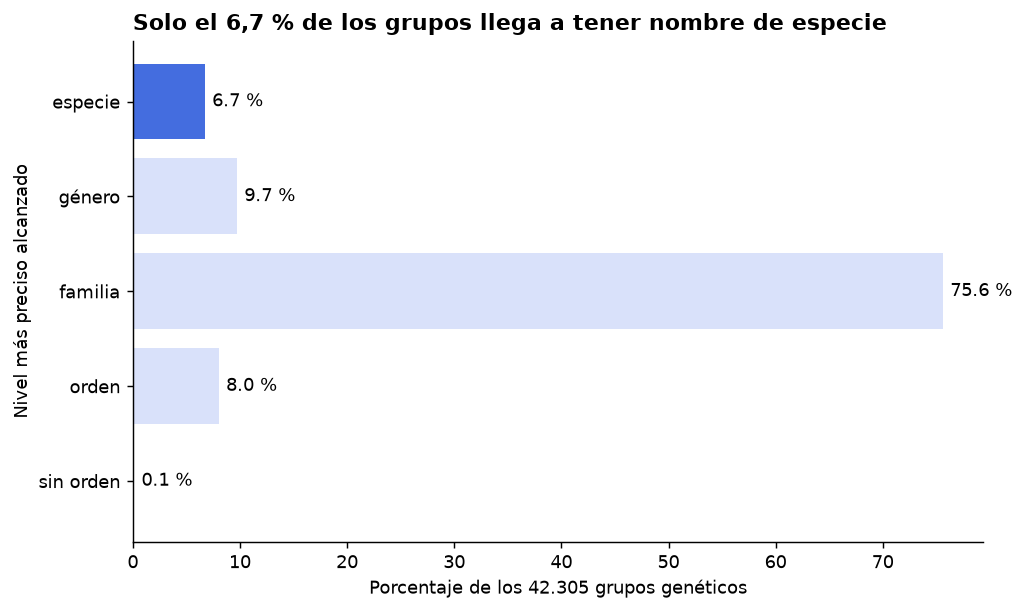

In [4]:
# ordeno los niveles desde el nombre más preciso hasta la clasificación más general
orden_niveles = ['especie', 'género', 'familia', 'orden', 'sin orden']
grafico_niveles = niveles.set_index('nivel_maximo').reindex(orden_niveles).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4.8))
colores = [color_nebula] + [color_claro] * 4
ax.barh(grafico_niveles.index[::-1], grafico_niveles['porcentaje'][::-1], color=colores[::-1])
ax.set_title('Solo el 6,7 % de los grupos llega a tener nombre de especie', loc='left', weight='bold')
ax.set_xlabel('Porcentaje de los 42.305 grupos genéticos')
ax.set_ylabel('Nivel más preciso alcanzado')
for i, valor in enumerate(grafico_niveles['porcentaje'][::-1]):
    ax.text(valor + 0.7, i, f'{valor:.1f} %', va='center')
fig.tight_layout()
fig.savefig(ruta_imagenes / 'nivel_identificacion.png', bbox_inches='tight')
plt.show()

## Las moscas y las avispas reúnen el mayor vacío

Comparo únicamente órdenes con al menos 100 BIN para evitar que unos pocos casos produzcan porcentajes espectaculares. Himenópteros y dípteros superan el 94 % de anonimato y, además, reúnen casi 30.000 grupos genéticos. Mariposas y polillas presentan un índice menor, aunque todavía supera el 81 %.

El gráfico no mide cuántas especies son nuevas. Mide cuántos códigos genéticos siguen sin estar enlazados con una identificación de especie en esta tabla.

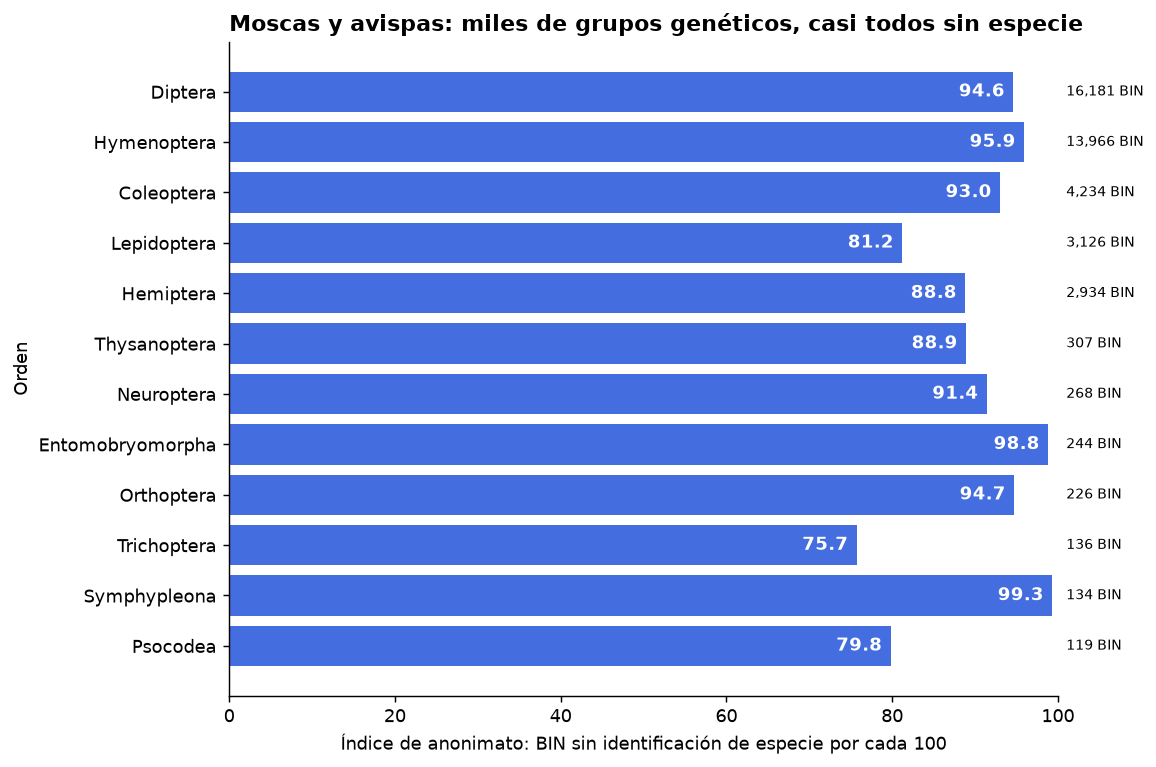

In [5]:
# selecciono órdenes con base suficiente y muestro volumen e índice juntos
ordenes_grandes = ordenes.loc[ordenes['grupos_geneticos'] >= 100].copy()
ordenes_grandes = ordenes_grandes.sort_values('grupos_geneticos').tail(12)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ordenes_grandes['orden'], ordenes_grandes['indice_anonimato'], color=color_nebula)
ax.set_xlim(0, 100)
ax.set_title('Moscas y avispas: miles de grupos genéticos, casi todos sin especie', loc='left', weight='bold')
ax.set_xlabel('Índice de anonimato: BIN sin identificación de especie por cada 100')
ax.set_ylabel('Orden')
for i, fila in enumerate(ordenes_grandes.itertuples()):
    ax.text(fila.indice_anonimato - 1, i, f'{fila.indice_anonimato:.1f}', ha='right', va='center', color='white', weight='bold')
    ax.text(101, i, f'{fila.grupos_geneticos:,} BIN', va='center', fontsize=8)
fig.tight_layout()
fig.savefig(ruta_imagenes / 'anonimato_ordenes.png', bbox_inches='tight')
plt.show()

## Lo raro resulta todavía más difícil de nombrar

Los BIN observados una sola vez alcanzan un índice de 98,1. El anonimato baja a medida que aumenta el número de ejemplares, pero incluso entre los grupos con más de 20 registros permanece en el 80,7 %.

La relación no demuestra por sí sola una causa. Un grupo puede aparecer poco porque sea raro, porque viva donde se muestreó menos o porque el método de captura no le favorezca. Aun así, el patrón ayuda a entender el trabajo pendiente: los grupos menos vistos son también aquellos con menos posibilidades de quedar enlazados con una especie conocida.

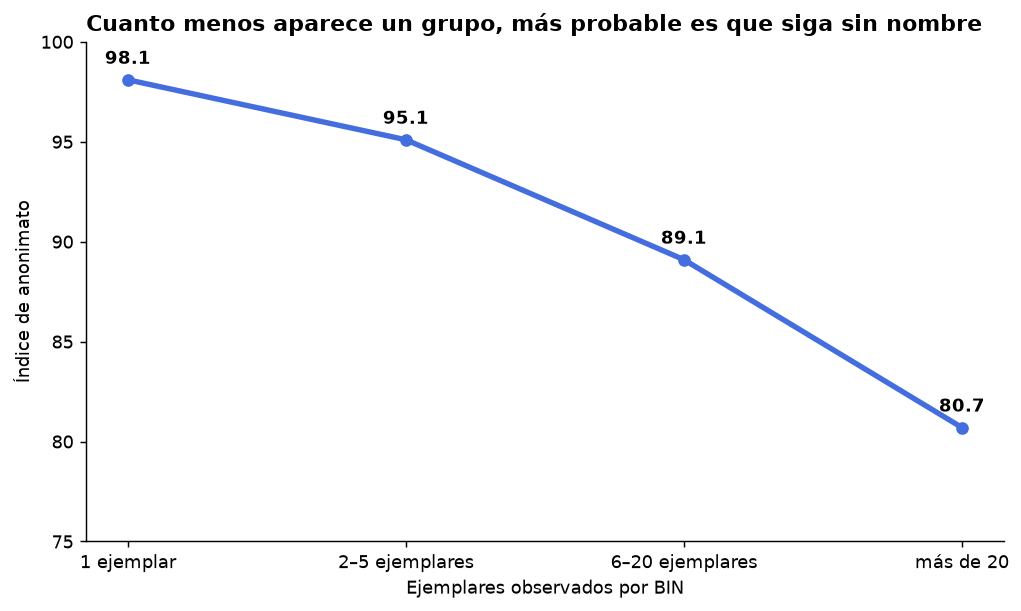

In [6]:
# mantengo los tramos en un orden intuitivo para comparar rareza y anonimato
orden_rareza = ['1 ejemplar', '2–5 ejemplares', '6–20 ejemplares', 'más de 20']
rareza_grafico = rareza.set_index('tramo_ejemplares').reindex(orden_rareza).reset_index()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(rareza_grafico['tramo_ejemplares'], rareza_grafico['indice_anonimato'], marker='o', lw=3, color=color_nebula)
ax.set_ylim(75, 100)
ax.set_title('Cuanto menos aparece un grupo, más probable es que siga sin nombre', loc='left', weight='bold')
ax.set_ylabel('Índice de anonimato')
ax.set_xlabel('Ejemplares observados por BIN')
for i, fila in rareza_grafico.iterrows():
    ax.text(i, fila['indice_anonimato'] + 0.8, f"{fila['indice_anonimato']:.1f}", ha='center', weight='bold')
fig.tight_layout()
fig.savefig(ruta_imagenes / 'anonimato_rareza.png', bbox_inches='tight')
plt.show()

## El territorio cambia menos que el tipo de insecto

Entre las trece ecorregiones analizadas, el índice va del 75,3 % en Northern Basin and Range al 90,1 % en Mojave Basin and Range. Las diferencias por orden son más extremas y tienen una interpretación más directa.

No utilizo este resultado para declarar un mapa definitivo del desconocimiento. Un mismo BIN puede aparecer en varias regiones y el esfuerzo de muestreo fue desigual. La comparación territorial sirve como pista, no como clasificación ecológica cerrada.

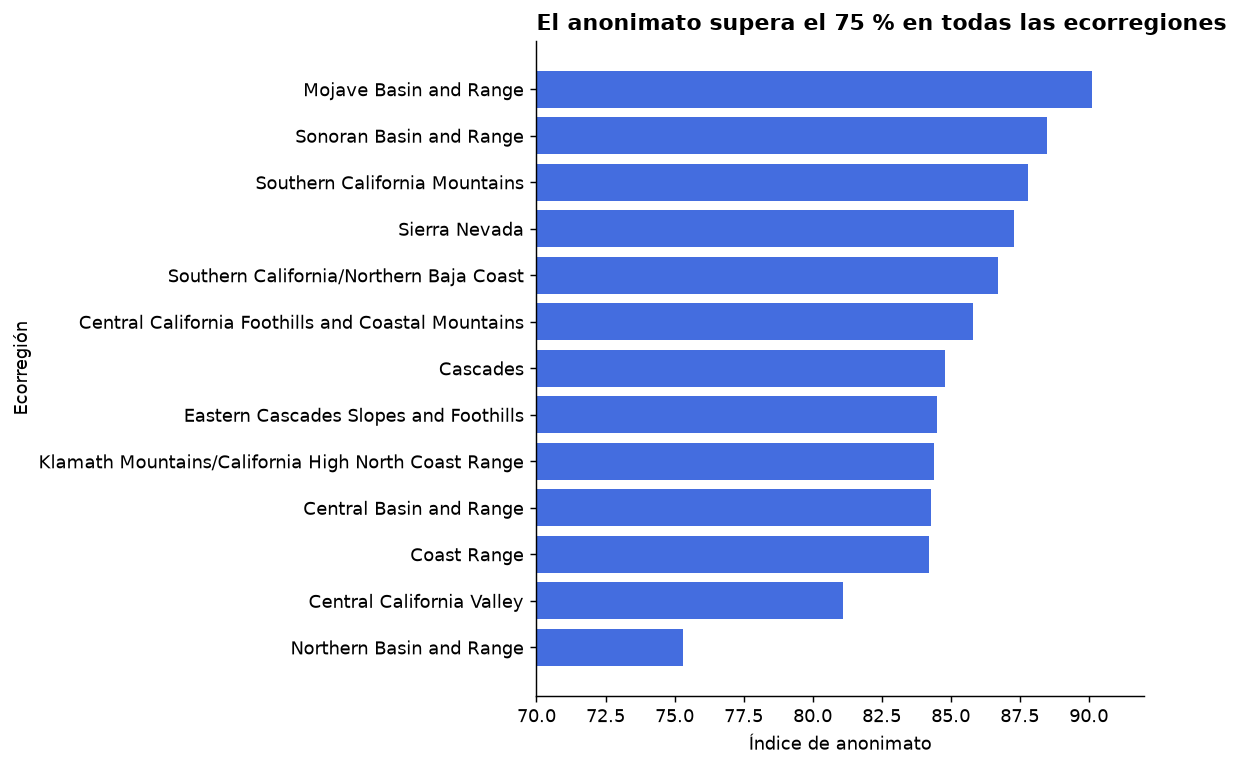

In [7]:
# muestro las regiones ordenadas sin confundir presencia con abundancia
regiones_grafico = regiones.sort_values('indice_anonimato')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(regiones_grafico['US_L3NAME'], regiones_grafico['indice_anonimato'], color=color_nebula)
ax.set_xlim(70, 92)
ax.set_title('El anonimato supera el 75 % en todas las ecorregiones', loc='left', weight='bold')
ax.set_xlabel('Índice de anonimato')
ax.set_ylabel('Ecorregión')
fig.tight_layout()
fig.savefig(ruta_imagenes / 'anonimato_ecorregiones.png', bbox_inches='tight')
plt.show()

## Limitaciones

- Un BIN no coincide siempre de manera perfecta con una especie biológica.
- La ausencia de nombre en esta descarga no demuestra que la especie sea nueva para la ciencia.
- El catálogo refleja el estado de las identificaciones cuando los autores descargaron BOLD el 25 de junio de 2025.
- Las trampas Malaise aportaron la gran mayoría de ejemplares y favorecen determinados insectos voladores.
- El muestreo territorial y temporal no fue idéntico en todos los lugares.
- El índice mide un vacío de identificación dentro de este conjunto, no todo el conocimiento entomológico de California.

## Conclusión

El ADN permitió separar **42.305 grupos genéticos**, pero solo **2.817** quedaron enlazados con un nombre de especie. Mi índice de anonimato alcanza así **93,3 sobre 100**.

El vacío se concentra en los dos grandes protagonistas del conjunto, moscas y avispas, y se vuelve todavía mayor entre los grupos observados una sola vez. El análisis no descubre 39.488 especies nuevas. Muestra algo distinto: la tecnología ya distingue una diversidad que la taxonomía todavía no ha podido convertir en un catálogo de nombres.